In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
import seaborn as sns
import os

In [ ]:
df=pd.read_csv(r'D:\Times_eries_Analysis\Datasets\wp_log_peyton_manning.csv')

In [5]:
from pathlib import Path
base_dir = Path.cwd()
data_path = base_dir / 'Datasets' / 'wp_log_peyton_manning.csv'
print('Loading data from:', data_path)
if not data_path.exists():
    raise FileNotFoundError(f'Data file not found: {data_path}')
df = pd.read_csv(data_path)

Loading data from: d:\Times_eries_Analysis\Datasets\wp_log_peyton_manning.csv


In [4]:
df.head(10)

,ds,y
0,2007-12-10,9.590761
1,2007-12-11,8.519590
2,2007-12-12,8.183677
3,2007-12-13,8.072467
4,2007-12-14,7.893572
5,2007-12-15,7.783641
6,2007-12-16,8.414052
7,2007-12-17,8.829226
8,2007-12-18,8.382518
9,2007-12-19,8.069655


In [ ]:
#convert 'ds' column to datetime
df['ds'] = pd.to_datetime(df['ds'])

#set 'ds' as the index
df.set_index('ds', inplace=True)

#display the first few rows of the dataframe
print(df.head())

                   y
ds                  
2007-12-10  9.590761
2007-12-11  8.519590
2007-12-12  8.183677
2007-12-13  8.072467
2007-12-14  7.893572


In [10]:
!pip uninstall matplotlib matplotlib-inline -y
!pip install matplotlib==3.7.2 matplotlib-inline==0.1.6

Found existing installation: matplotlib 3.5.3
Uninstalling matplotlib-3.5.3:
  Successfully uninstalled matplotlib-3.5.3


ERROR: Exception:
Traceback (most recent call last):
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_internal\cli\base_command.py", line 228, in _main
    status = self.run(options, args)
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_internal\commands\uninstall.py", line 93, in run
    uninstall_pathset.commit()
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_internal\req\req_uninstall.py", line 450, in commit
    self._moved_paths.commit()
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_internal\req\req_uninstall.py", line 290, in commit
    save_dir.cleanup()
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_internal\utils\temp_dir.py", line 199, in cleanup
    rmtree(ensure_text(self._path))
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_vendor\retrying.py", line 49, in wrapped_f
    return Retrying(*dargs, **dkw).call(f, *args, **kw)
  File "d:\times_eries_analysis\env\lib\site-packages\pip\_vendor\retrying.py", lin

  Using cached matplotlib_inline-0.1.6-py3-none-any.whl (9.4 kB)
  Using cached contourpy-1.3.0-cp39-cp39-win_amd64.whl (211 kB)
  Using cached importlib_resources-6.5.2-py3-none-any.whl (37 kB)
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 3.3.1
    Uninstalling pyparsing-3.3.1:
      Successfully uninstalled pyparsing-3.3.1
  Attempting uninstall: matplotlib-inline
    Found existing installation: matplotlib-inline 0.2.1
    Uninstalling matplotlib-inline-0.2.1:
      Successfully uninstalled matplotlib-inline-0.2.1


You should consider upgrading via the 'd:\times_eries_analysis\env\scripts\python.exe -m pip install --upgrade pip' command.


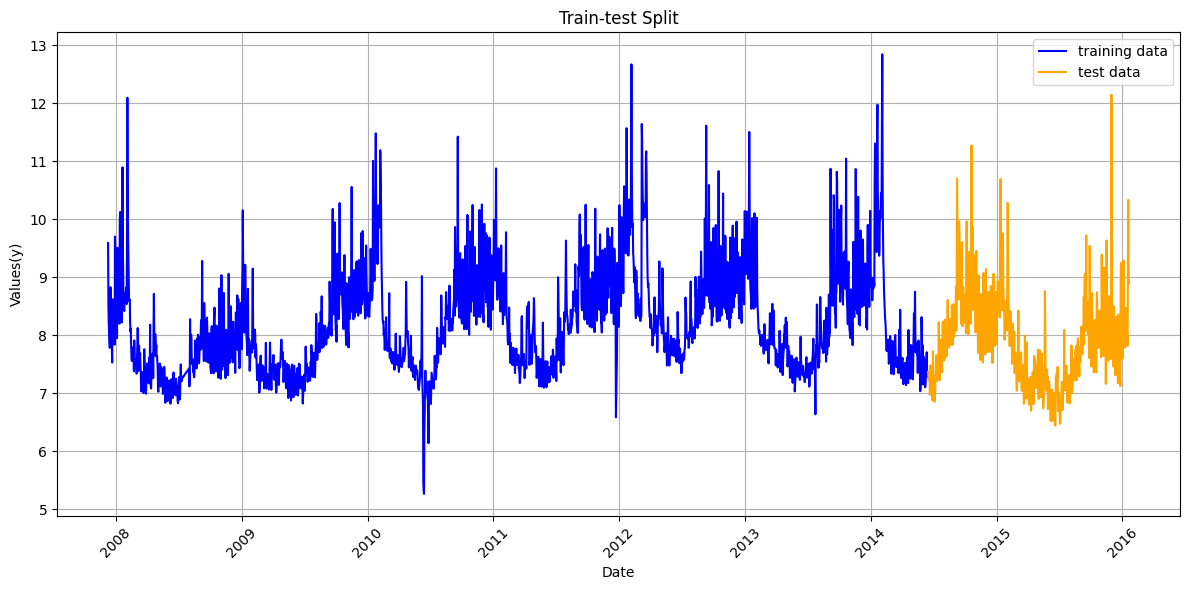

In [11]:
#split the data into training and testing sets based on date
train_size=int(len(df)*0.8) #80% for training
train, test = df[0:train_size], df[train_size:]

#plot the training and testing data
plt.figure(figsize=(12,6))
plt.plot(train.index, train['y'], label='training data',color='blue')
plt.plot(test.index, test['y'], label='test data', color='orange')
plt.title('Train-test Split')
plt.xlabel('Date')
plt.ylabel('Values(y)')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#plot the time series data with enhanced aesthetics
plt.figure(figsize=(12,6))
sns.set(style="darkgrid")
